# Propuesta definitiva · Estadística No Paramétrica
Base **Wine (UCI)**: descarga, análisis y gráficos.

- **P1:** Kruskal–Wallis + Dunn (Holm) sobre la prolina por cultivar.
- **S1:** KDE con h fijo vs h variable (Abramson) desde cero, h por validación cruzada dejando uno fuera, y Wilcoxon sobre las diferencias por vino.
- **S2:** Mann–Whitney unilateral sobre flavonoides, cultivar 1 vs cultivar 3.

## 0. Descarga y preparación de los datos

In [1]:
%pip install -q ucimlrepo

In [2]:
import datetime
from ucimlrepo import fetch_ucirepo

wine = fetch_ucirepo(id=109)   # Wine, UCI Machine Learning Repository
X, y = wine.data.features.copy(), wine.data.targets

X.columns = ["alcohol", "ac_malico", "ceniza", "alcal_ceniza", "magnesio",
             "fenoles_tot", "flavonoides", "fenoles_noflav", "proantocianinas",
             "int_color", "tono", "od280_od315", "prolina"]
X.insert(0, "id_vino", [f"Vino_{i:03d}" for i in range(1, len(X) + 1)])
X["cultivar"] = "Cultivar " + y.iloc[:, 0].astype(str)

X.to_csv("wine_uci.csv", index=False)
print("Descarga ejecutada el", datetime.date.today())
print(X.shape)                                    # esperado: (178, 15)
print(X["cultivar"].value_counts().sort_index())  # esperado: 59, 71, 48

Descarga ejecutada el 2026-10-26
(178, 15)
cultivar
Cultivar 1    59
Cultivar 2    71
Cultivar 3    48
Name: count, dtype: int64


## 1. Librerías y lectura

In [3]:
%matplotlib inline
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
df = pd.read_csv("wine_uci.csv")   # generado por la celda de descarga
cultivares = sorted(df["cultivar"].unique())
print("n =", len(df), df["cultivar"].value_counts().sort_index().to_dict())

n = 178 {'Cultivar 1': 59, 'Cultivar 2': 71, 'Cultivar 3': 48}


## 2. Utilidades (Holm)

In [4]:
# =====================================================================
# Utilidades: Holm
# =====================================================================
def holm(p):
    p = np.asarray(p, float)
    m = len(p)
    orden = np.argsort(p)
    ajust = np.empty(m)
    corrido = 0.0
    for k, i in enumerate(orden):
        corrido = max(corrido, (m - k) * p[i])
        ajust[i] = min(1.0, corrido)
    return ajust

## 3. P1 · Kruskal–Wallis + Dunn con Holm (prolina por cultivar)
H0: igual distribución de la prolina en los tres cultivares; H1: al menos dos difieren.

In [5]:
# =====================================================================
# P1. Kruskal-Wallis con corrección por empates y Dunn con Holm (desde cero)
# =====================================================================
def kruskal_wallis(grupos):
    todos = np.concatenate(grupos)
    N = len(todos)
    r = stats.rankdata(todos)
    lim = np.cumsum([0] + [len(g) for g in grupos])
    rangos = [r[lim[k]:lim[k + 1]] for k in range(len(grupos))]
    H = 12 / (N * (N + 1)) * sum(len(rk) * rk.mean() ** 2 for rk in rangos) - 3 * (N + 1)
    _, t = np.unique(todos, return_counts=True)
    C = 1 - (t ** 3 - t).sum() / (N ** 3 - N)          # corrección por empates
    H = H / C
    p = stats.chi2.sf(H, len(grupos) - 1)
    eps2 = H / (N - 1)                                   # tamaño del efecto
    return H, p, eps2, rangos, t, N

def dunn_holm(grupos, nombres):
    H, p, eps2, rangos, t, N = kruskal_wallis(grupos)
    sigma2 = N * (N + 1) / 12 - (t ** 3 - t).sum() / (12 * (N - 1))   # con empates
    filas = []
    for i in range(len(grupos)):
        for j in range(i + 1, len(grupos)):
            ni, nj = len(grupos[i]), len(grupos[j])
            z = (rangos[i].mean() - rangos[j].mean()) / np.sqrt(sigma2 * (1 / ni + 1 / nj))
            pb = 2 * stats.norm.sf(abs(z))
            A = stats.mannwhitneyu(grupos[i], grupos[j]).statistic / (ni * nj)  # P(X_i > X_j) + 0.5 P(=)
            filas.append((nombres[i], nombres[j], z, pb, A))
    res = pd.DataFrame(filas, columns=["grupo_i", "grupo_j", "z", "p_bruto", "prob_superioridad"])
    res["p_Holm"] = holm(res["p_bruto"].values)
    return res

print("\n=== P1: prolina por cultivar ===")
g_prol = [df.loc[df.cultivar == c, "prolina"].values for c in cultivares]
H, p, eps2, *_ = kruskal_wallis(g_prol)
print(f"Kruskal-Wallis (desde cero): H = {H:.3f}, p = {p:.3g}, eps2_H = {eps2:.3f}")
sp = stats.kruskal(*g_prol)
print(f"scipy.stats.kruskal:         H = {sp.statistic:.3f}, p = {sp.pvalue:.3g}")
print(dunn_holm(g_prol, cultivares).round(4).to_string(index=False))
try:
    import scikit_posthocs as sp_
    print("scikit_posthocs.posthoc_dunn (Holm):")
    print(sp_.posthoc_dunn(df, val_col="prolina", group_col="cultivar", p_adjust="holm").round(4))
except ImportError:
    print("(opcional) pip install scikit-posthocs para comparar con posthoc_dunn")

print("Fligner-Killeen (dispersiones iguales):", stats.fligner(*g_prol))

# Verificación del fundamento: bajo H0 y sin empates, E(H) = k - 1
def simula_EH(tamanos, B=5000):
    Hs = np.empty(B)
    for b in range(B):
        Hs[b] = kruskal_wallis([rng.normal(size=n) for n in tamanos])[0]
    return Hs.mean()
print(f"Simulación E(H) con k=3: {simula_EH([len(g) for g in g_prol]):.3f} (teórico = 2)")


=== P1: prolina por cultivar ===
Kruskal-Wallis (desde cero): H = 119.060, p = 1.4e-26, eps2_H = 0.673
scipy.stats.kruskal:         H = 119.060, p = 1.4e-26
   grupo_i    grupo_j       z  p_bruto  prob_superioridad  p_Holm
Cultivar 1 Cultivar 2 10.7571   0.0000             0.9866  0.0000
Cultivar 1 Cultivar 3  6.9138   0.0000             0.9806  0.0000
Cultivar 2 Cultivar 3 -2.9493   0.0032             0.2644  0.0032
(opcional) pip install scikit-posthocs para comparar con posthoc_dunn
Fligner-Killeen (dispersiones iguales): FlignerResult(statistic=np.float64(14.406314033533539), pvalue=np.float64(0.000744232541068513))
Simulación E(H) con k=3: 1.948 (teórico = 2)


## 4. S1 · Densidad de la prolina: h fijo vs h variable
H0: mediana de d_i = 0; H1: mediana de d_i > 0 (gana el ancho variable).

In [6]:
# =====================================================================
# S1. KDE gaussiano con h fijo y h variable (Abramson), desde cero
# =====================================================================
def kde_fijo(x_eval, datos, h):
    z = (np.asarray(x_eval)[:, None] - datos[None, :]) / h
    return np.exp(-0.5 * z ** 2).sum(1) / (len(datos) * h * np.sqrt(2 * np.pi))

def lambdas_abramson(datos, h0, alpha=0.5):
    piloto = np.maximum(kde_fijo(datos, datos, h0), 1e-300)
    g = np.exp(np.mean(np.log(piloto)))                  # media geométrica
    return (piloto / g) ** (-alpha)

def kde_variable(x_eval, datos, h, h0, alpha=0.5):
    hi = h * lambdas_abramson(datos, h0, alpha)
    z = (np.asarray(x_eval)[:, None] - datos[None, :]) / hi[None, :]
    return (np.exp(-0.5 * z ** 2) / (hi[None, :] * np.sqrt(2 * np.pi))).mean(1)

def silverman(x):
    return 0.9 * min(x.std(ddof=1), stats.iqr(x) / 1.34) * len(x) ** (-0.2)

def loo_fijo(datos, hs):
    n = len(datos)
    ll = np.empty((len(hs), n))
    for i in range(n):
        d = np.delete(datos, i)
        zi = datos[i] - d
        for a, h in enumerate(hs):
            f = np.mean(np.exp(-0.5 * (zi / h) ** 2) / (h * np.sqrt(2 * np.pi)))
            ll[a, i] = np.log(max(f, 1e-300))
    return ll

def loo_variable(datos, hs, h0, alpha=0.5):
    n = len(datos)
    ll = np.empty((len(hs), n))
    for i in range(n):
        d = np.delete(datos, i)                          # el piloto tampoco usa x_i
        lam = lambdas_abramson(d, h0, alpha)
        zi = datos[i] - d
        for a, h in enumerate(hs):
            hi = h * lam
            f = np.mean(np.exp(-0.5 * (zi / hi) ** 2) / (hi * np.sqrt(2 * np.pi)))
            ll[a, i] = np.log(max(f, 1e-300))
    return ll

print("\n=== S1: densidad de la prolina, h fijo vs h variable ===")
x = df["prolina"].values.astype(float)
h0 = silverman(x)
hs = h0 * np.geomspace(0.2, 3.0, 40)

# Validación contra scipy (h fijo): gaussian_kde usa h = factor * sd
rejilla = np.linspace(x.min() - 150, x.max() + 150, 400)
h_prueba = h0
f_mio = kde_fijo(rejilla, x, h_prueba)
f_scipy = stats.gaussian_kde(x, bw_method=h_prueba / x.std(ddof=1))(rejilla)
print("KDE fijo propio == scipy.gaussian_kde:", np.allclose(f_mio, f_scipy))
# En R: density(x, bw = h_prueba, kernel = "gaussian") debe dar lo mismo;
#       density(x, bw = "SJ") para el ancho de Sheather-Jones.

ll_f = loo_fijo(x, hs)
ll_v = loo_variable(x, hs, h0)
a_f, a_v = ll_f.mean(1).argmax(), ll_v.mean(1).argmax()
h_f, h_v = hs[a_f], hs[a_v]
print(f"h0 (Silverman) = {h0:.1f} | h fijo óptimo = {h_f:.1f} | h variable óptimo = {h_v:.1f}")
print(f"log-verosimilitud LOO media: fijo = {ll_f[a_f].mean():.4f}, variable = {ll_v[a_v].mean():.4f}")

d = ll_v[a_v] - ll_f[a_f]                                # d_i por vino
print(f"Ganancia media por vino (variable - fijo) = {d.mean():.4f}")
w = stats.wilcoxon(d, alternative="greater")
dnz = d[d != 0]
rangos = stats.rankdata(np.abs(dnz))
r_rb = (rangos[dnz > 0].sum() - rangos[dnz < 0].sum()) / rangos.sum()
print(f"Wilcoxon (H1: mediana d > 0): W = {w.statistic:.1f}, p = {w.pvalue:.4g}, r_rb = {r_rb:.3f}")

# Permutación de signos sobre la media de d_i (la validación cruzada induce dependencia leve)
B = 20000
signos = rng.choice([-1, 1], size=(B, len(d)))
perm = (signos * d).mean(1)
p_perm = (np.sum(perm >= d.mean()) + 1) / (B + 1)
print(f"Permutación de signos (media de d_i): p = {p_perm:.4g}")


=== S1: densidad de la prolina, h fijo vs h variable ===
KDE fijo propio == scipy.gaussian_kde: True
h0 (Silverman) = 100.5 | h fijo óptimo = 57.0 | h variable óptimo = 37.6
log-verosimilitud LOO media: fijo = -7.0577, variable = -7.0573
Ganancia media por vino (variable - fijo) = 0.0004
Wilcoxon (H1: mediana d > 0): W = 7719.0, p = 0.6399, r_rb = -0.031
Permutación de signos (media de d_i): p = 0.4896


### Gráfico: histograma y KDE (h fijo vs h variable)

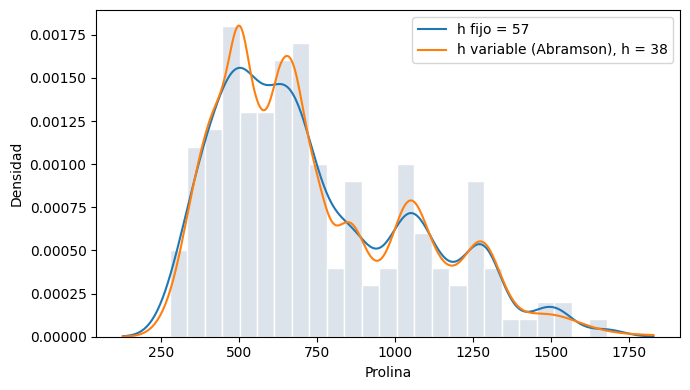

In [7]:
# Gráfico: histograma + KDE fijo + KDE variable
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(x, bins=25, density=True, color="#DDE3EA", edgecolor="white")
ax.plot(rejilla, kde_fijo(rejilla, x, h_f), label=f"h fijo = {h_f:.0f}")
ax.plot(rejilla, kde_variable(rejilla, x, h_v, h0), label=f"h variable (Abramson), h = {h_v:.0f}")
ax.set_xlabel("Prolina"); ax.set_ylabel("Densidad"); ax.legend()
fig.tight_layout(); fig.savefig("densidad_prolina.png", dpi=150); plt.show()

### Gráfico: KDE por cultivar (condición de forma similar de P1)

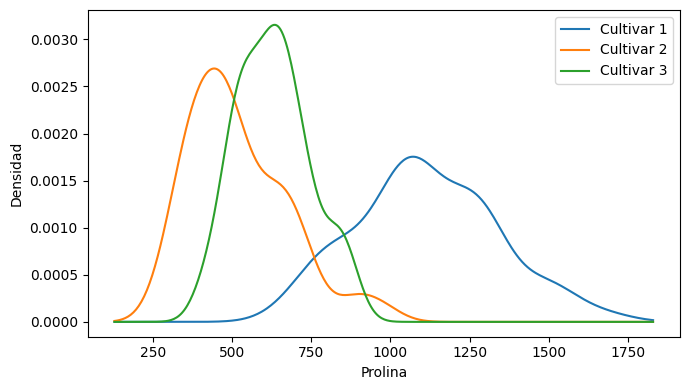

In [8]:
# KDE por cultivar (para revisar la condición de forma similar de P1)
fig, ax = plt.subplots(figsize=(7, 4))
for c, g in zip(cultivares, g_prol):
    hc = silverman(g.astype(float))
    ax.plot(rejilla, kde_fijo(rejilla, g.astype(float), hc), label=c)
ax.set_xlabel("Prolina"); ax.set_ylabel("Densidad"); ax.legend()
fig.tight_layout(); fig.savefig("kde_prolina_por_cultivar.png", dpi=150); plt.show()

## 5. S2 · Mann–Whitney unilateral (flavonoides, cultivar 1 vs 3)
H0: F1 = F3; H1: P(X1 > X3) > 1/2.

In [9]:
# =====================================================================
# S2. Mann-Whitney unilateral: flavonoides, cultivar 1 vs cultivar 3
# =====================================================================
print("\n=== S2: flavonoides, Cultivar 1 vs Cultivar 3 ===")
a = df.loc[df.cultivar == "Cultivar 1", "flavonoides"].values
b = df.loc[df.cultivar == "Cultivar 3", "flavonoides"].values
mw = stats.mannwhitneyu(a, b, alternative="greater")      # H1: P(X1 > X3) > 1/2
A = mw.statistic / (len(a) * len(b))
print(f"U = {mw.statistic:.1f}, p = {mw.pvalue:.3g}")
print(f"Probabilidad de superioridad A = {A:.3f}; correlación biserial de rangos r = {2 * A - 1:.3f}")
print("Fligner-Killeen (cultivar 1 vs 3):", stats.fligner(a, b))


=== S2: flavonoides, Cultivar 1 vs Cultivar 3 ===
U = 2832.0, p = 3.76e-19
Probabilidad de superioridad A = 1.000; correlación biserial de rangos r = 1.000
Fligner-Killeen (cultivar 1 vs 3): FlignerResult(statistic=np.float64(5.464890964569547), pvalue=np.float64(0.019402264643972884))
